# Analysis of Socio-Demographic Factors and Building Structures in Relation to Severe Damage from the 2015 Nepal Earthquake in Gorkha: Logistic Regression, Odds Ratio, and Municipality-Level Analysis

1. Import Library

- pandas, numpy, matplotlib: olah data dan grafik.
- duckdb: query database langsung ke file nepal.sqlite.
- LogisticRegression, train_test_split, accuracy_score: model dan evaluasi.
- OneHotEncoder, Pipeline: encoding kategori dan alur model.

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from category_encoders import OneHotEncoder
from sklearn.pipeline import Pipeline

# Set display options
pd.set_option('display.max_columns', None)

2. Melihat Tabel Demografi

- duckdb.connect('./nepal.sqlite') lalu SELECT * FROM household_demographics LIMIT 5.
- Kolom berisi gender, usia kepala keluarga, kasta, pendidikan, pendapatan, ukuran keluarga, dan kepemilikan rekening bank.

In [21]:
# Connect to database
conn = duckdb.connect('./nepal.sqlite')

# Query household_demographics table
df_demo = conn.execute("""
    SELECT *
    FROM household_demographics
    LIMIT 5
""").df()

conn.close()

print(f"Shape: {df_demo.shape}")
print("\nColumns:", df_demo.columns.tolist())
print("\nFirst 5 rows:")
print(df_demo)

Shape: (5, 8)

Columns: ['household_id', 'gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household', 'size_household', 'is_bank_account_present_in_household']

First 5 rows:
   household_id gender_household_head  age_household_head caste_household  \
0           101                  Male                31.0             Rai   
1           201                Female                62.0             Rai   
2           301                  Male                51.0   Gharti/Bhujel   
3           401                  Male                48.0   Gharti/Bhujel   
4           501                  Male                70.0   Gharti/Bhujel   

  education_level_household_head income_level_household  size_household  \
0                     Illiterate        Rs. 10 thousand             3.0   
1                     Illiterate        Rs. 10 thousand             6.0   
2                     Illiterate        Rs. 10 thousand            13.0 

3. Jumlah Rumah Tangga

- COUNT(*): 249.932 rumah tangga.

In [22]:
conn = duckdb.connect('./nepal.sqlite')

count_df = conn.execute("""
    SELECT COUNT(*) as count
    FROM household_demographics
""").df()

conn.close()

demo_count = count_df.loc[0, 'count']
print(f"Number of households: {demo_count}")

Number of households: 249932


4. Uji JOIN 4 Tabel

- Menggabungkan household_demographics, id_map, building_structure, dan building_damage untuk distrik 4 (Gorkha), LIMIT 5 sebagai uji.
- Hasil: 26 kolom (demografi + struktur bangunan + vdcmun_id + damage_grade).

In [23]:
district_id = 4

conn = duckdb.connect('./nepal.sqlite')

query = f"""
    SELECT
        h.*,
        s.*,
        i.vdcmun_id,
        d.damage_grade
    FROM household_demographics h
    JOIN id_map i ON h.household_id = i.household_id
    JOIN building_structure s ON i.building_id = s.building_id
    JOIN building_damage d ON i.building_id = d.building_id
    WHERE i.district_id = {district_id}
    LIMIT 5
"""

df_joined = conn.execute(query).df()
conn.close()

print(f"Shape: {df_joined.shape}")
print(f"\nColumns: {df_joined.columns.tolist()}")
print("\nFirst few rows:")
print(df_joined.head())

Shape: (5, 26)

Columns: ['household_id', 'gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household', 'size_household', 'is_bank_account_present_in_household', 'building_id', 'count_floors_pre_eq', 'count_floors_post_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'height_ft_post_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'condition_post_eq', 'superstructure', 'vdcmun_id', 'damage_grade']

First few rows:
   household_id gender_household_head  age_household_head caste_household  \
0      16481701                Female                19.0        Chhetree   
1      16484101                Female                23.0        Chhetree   
2      16486201                  Male                50.0        Chhetree   
3      16533301                  Male                42.0        Chhetree   
4      16533401                

5. Memuat Data Lengkap dan Membuat Target

- Query yang sama tanpa LIMIT.
- .assign(severe_damage=...str.contains('Grade 4|Grade 5')) membuat target biner.
- .set_index('household_id') menjadikan ID sebagai index.
- .drop(columns=cols_to_drop) membuang kolom bocor (*_post_eq, building_id, damage_grade, count_floors_pre_eq) agar tidak terjadi data leakage.
- Hasil: 75.883 baris × 20 kolom, kerusakan parah 63,10%.

In [24]:
conn = duckdb.connect('./nepal.sqlite')

query = """
    SELECT
        h.*,
        s.*,
        i.vdcmun_id,
        d.damage_grade
    FROM household_demographics h
    JOIN id_map i ON h.household_id = i.household_id
    JOIN building_structure s ON i.building_id = s.building_id
    JOIN building_damage d ON i.building_id = d.building_id
    WHERE i.district_id = 4
"""

# Load data
df = conn.execute(query).df()
conn.close()

# Create binary target, set index, and drop leaky columns
cols_to_drop = [col for col in df.columns if 'post_eq' in col] + \
               ['building_id', 'damage_grade', 'count_floors_pre_eq']

df = (df
  .assign(severe_damage=df['damage_grade']           # <--- Create binary target column
    .str.contains('Grade 4|Grade 5')                 # <--- Check if grade contains 4 or 5
    .astype(int))                                    # <--- Convert to 0/1 integer
  .set_index('household_id')                         # <--- Use household_id as row index
  .drop(columns=cols_to_drop))                       # <--- Remove post-earthquake and other leaky columns

print(f"Final shape: {df.shape}")
print(f"Severe damage rate: {df['severe_damage'].mean():.2%}")

Final shape: (75883, 20)
Severe damage rate: 63.10%


6. Cek Kardinalitas Kategori

- select_dtypes + nunique().
- Hasil: caste_household punya 63 kategori (terbanyak), lalu pendidikan 19, superstructure 11, dst.
- Kasta terbanyak: Gurung (15.119), Brahman-Hill (13.043), Chhetree (8.766).

In [25]:
# Check unique values in categorical columns
cat_cols = df.select_dtypes(include=['object', 'str']).columns       # <--- columns
cardinality = df[cat_cols].nunique().sort_values(ascending=False)    #<--- cat_cols

print("Categorical feature cardinality:")
print(cardinality)
print(f"\nTop 10 most common castes:")
print(df['caste_household'].value_counts().head(10))

Categorical feature cardinality:
caste_household                   63
education_level_household_head    19
superstructure                    11
plan_configuration                10
foundation_type                    5
income_level_household             5
ground_floor_type                  5
position                           4
other_floor_type                   4
roof_type                          3
land_surface_condition             3
gender_household_head              2
dtype: int64

Top 10 most common castes:
caste_household
Gurung          15119
Brahman-Hill    13043
Chhetree         8766
Magar            8180
Sarki            6052
Newar            5906
Kami             3565
Tamang           2396
Kumal            2271
Damai/Dholi      1977
Name: count, dtype: int64


7. Pengelompokan Kasta Langka

- Ambil 10 kasta terbanyak, sisanya diberi label Other memakai .apply(lambda ...).
- Hasil: 63 kategori menjadi 11, mengurangi jumlah kolom setelah one-hot encoding.

In [26]:
# Get top 10 castes
top_10_castes = (df['caste_household']
  .value_counts()                   # <--- Count frequency of each caste
  .head(10)                         # <--- Keep only top 10 most common
  .index)                           # <--- Extract caste names

# Group rare castes as "Other"
df = (df
  .assign(caste_household=df['caste_household'].apply(
      lambda c: c if c in top_10_castes else 'Other'  # <--- Keep top 10 castes, group rest as "Other"
  )))

print(f"Unique castes after grouping: {df['caste_household'].nunique()}")
print("\nCaste distribution:")
print(df['caste_household'].value_counts())

Unique castes after grouping: 11

Caste distribution:
caste_household
Gurung          15119
Brahman-Hill    13043
Chhetree         8766
Other            8608
Magar            8180
Sarki            6052
Newar            5906
Kami             3565
Tamang           2396
Kumal            2271
Damai/Dholi      1977
Name: count, dtype: int64


8. Fitur dan Target

- features = semua kolom kecuali target → X (75.883 × 19), y (75.883).

In [27]:
# Define target and features
target = 'severe_damage'
features = [col for col in df.columns if col != target]

# Create X and y
X = df[features]   # <-- feature matrix
y = df[target]   # <-- target vector

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFeatures include: {features[:5]}...")

X shape: (75883, 19)
y shape: (75883,)

Features include: ['gender_household_head', 'age_household_head', 'caste_household', 'education_level_household_head', 'income_level_household']...


9. Pembagian Data

- train_test_split(test_size=0.2, random_state=42): Train 60.706, Test 15.177.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training: {X_train.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")

Training: 60706 samples
Test: 15177 samples


10. Baseline

- Akurasi menebak kelas mayoritas: 63,17%.

In [29]:
baseline_acc = y_train.value_counts(normalize=True).max()
print(f"Baseline Accuracy: {baseline_acc:.4f}")

Baseline Accuracy: 0.6317


11. Model Regresi Logistik

- Pipeline: OneHotEncoder → LogisticRegression(max_iter=1000).
- Hasil: Train 73,04%, Test 72,36%, baseline 63,17%.
- Ada ConvergenceWarning (fitur numerik belum diskalakan).

In [30]:
# Build model
model = Pipeline([
    ('encoder', OneHotEncoder(use_cat_names=True)),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit model
model.fit(X_train, y_train)

# Evaluate
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")

C:\Users\jason\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Accuracy: 0.7304
Test Accuracy: 0.7236
Baseline Accuracy: 0.6317


12. Odds Ratio Faktor Risiko

- np.exp(coef_) diurutkan, 10 teratas diplot.
- Peningkat risiko terbesar: superstructure Stone (3,45x), atap Bamboo/Timber-Light (2,96x), superstructure Stone-mud mortar (2,46x), pondasi Other (2,46x), atap Heavy (2,44x), pondasi Mud mortar-Stone/Brick (2,25x).
- Menarik: kepala keluarga laki-laki (2,18x) dan denah Rectangular (2,07x) juga muncul.

Top 10 features INCREASING odds of severe damage:
plan_configuration_Rectangular            2.068091
other_floor_type_Timber-Planck            2.095343
gender_household_head_Male                2.175683
foundation_type_Mud mortar-Stone/Brick    2.251945
superstructure_Adobe/mud                  2.353322
roof_type_Bamboo/Timber-Heavy roof        2.443532
foundation_type_Other                     2.461384
superstructure_Stone, mud mortar          2.462909
roof_type_Bamboo/Timber-Light roof        2.956971
superstructure_Stone                      3.451532
dtype: float64


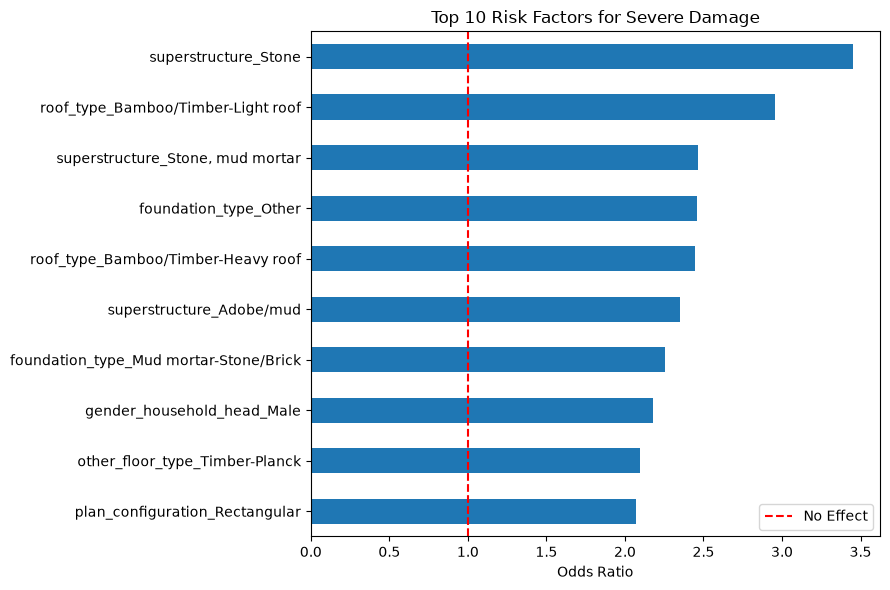

In [31]:
# Get feature names and coefficients
feature_names = model.named_steps['encoder'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]

# Create odds ratios
odds_ratios = pd.Series(np.exp(coefficients), index=feature_names).sort_values()

print("Top 10 features INCREASING odds of severe damage:")
print(odds_ratios.tail(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratios.tail(10).plot(kind='barh', ax=ax)
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Risk Factors for Severe Damage')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect')
ax.legend()
plt.tight_layout()
plt.show()

13. Kerusakan per Kotamadya

- groupby('vdcmun_id') menghitung rasio dan jumlah rumah.
- Tertinggi: ID 31 (93,0%), ID 32 (85,1%), ID 35 (82,7%), ID 30 (82,4%).
- Terendah: ID 37 (±43,8%).

Top 10 municipalities by damage rate:
           damage_rate  count
vdcmun_id                    
31            0.930199   4169
32            0.851117   7160
35            0.827145   3905
30            0.824201   6917
33            0.782464   6615
34            0.666979   2132
39            0.572344   7492
40            0.512444   6951
38            0.506425  11362
36            0.503972   5790


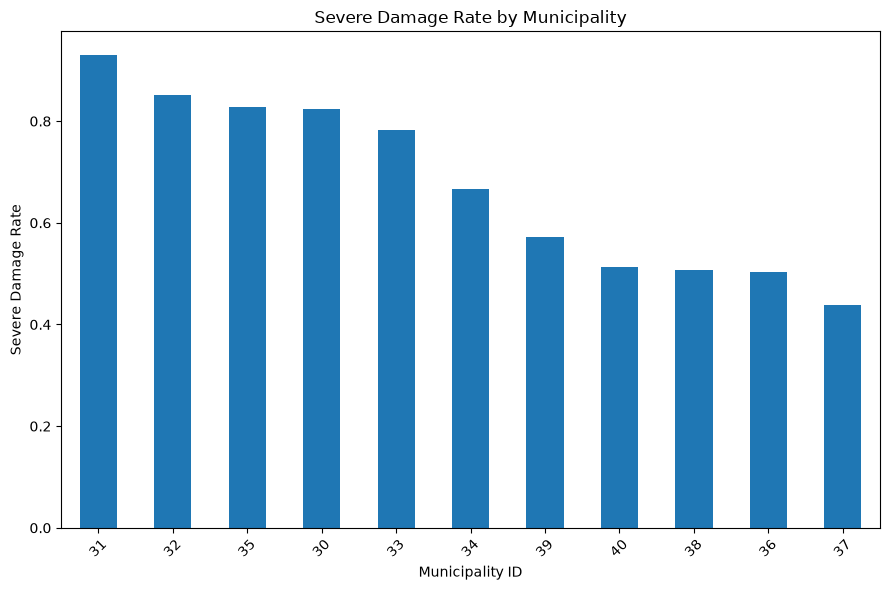

In [32]:
# Damage by municipality
damage_by_municipality = df.groupby('vdcmun_id')['severe_damage'].agg(['mean', 'count'])
damage_by_municipality.columns = ['damage_rate', 'count']
damage_by_municipality = damage_by_municipality.sort_values('damage_rate', ascending=False)

print("Top 10 municipalities by damage rate:")
print(damage_by_municipality.head(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
damage_by_municipality['damage_rate'].head(15).plot(kind='bar', ax=ax)
ax.set_xlabel('Municipality ID')
ax.set_ylabel('Severe Damage Rate')
ax.set_title('Severe Damage Rate by Municipality')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

14. Faktor Protektif

- 10 odds ratio terendah.
- Pelindung terkuat: pondasi RC (0,50), superstructure Brick-cement mortar (0,51), atap RCC/RB/RBC (0,60), lantai lain RCC (0,74), kasta Kumal (0,75).

Top 10 features DECREASING odds of severe damage (protective factors):
foundation_type_RC                     0.503066
superstructure_Brick, cement mortar    0.508896
roof_type_RCC/RB/RBC                   0.598920
other_floor_type_RCC/RB/RBC            0.741122
caste_household_Kumal                  0.745192
superstructure_RC, non-engineered      0.752384
superstructure_Timber                  0.800508
superstructure_Other                   0.808635
vdcmun_id                              0.810874
superstructure_Bamboo                  0.824042
dtype: float64


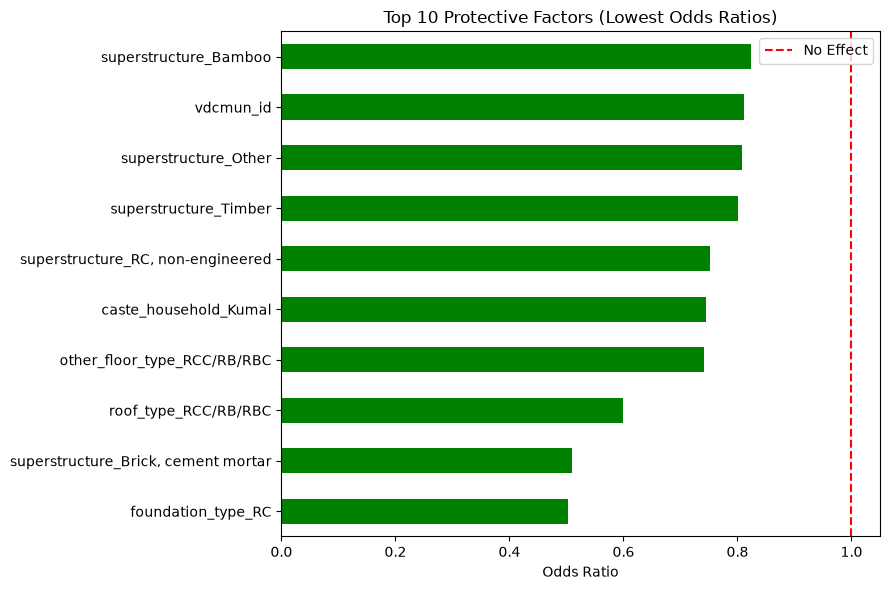

In [33]:
print("Top 10 features DECREASING odds of severe damage (protective factors):")
print(odds_ratios.head(10))

# Plot
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratios.head(10).plot(kind='barh', ax=ax, color='green')
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Protective Factors (Lowest Odds Ratios)')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect')
ax.legend()
plt.tight_layout()
plt.show()

15. Plot Garis per Kotamadya

- Garis rasio kerusakan per vdcmun_id untuk melihat pola 
antarwilayah.

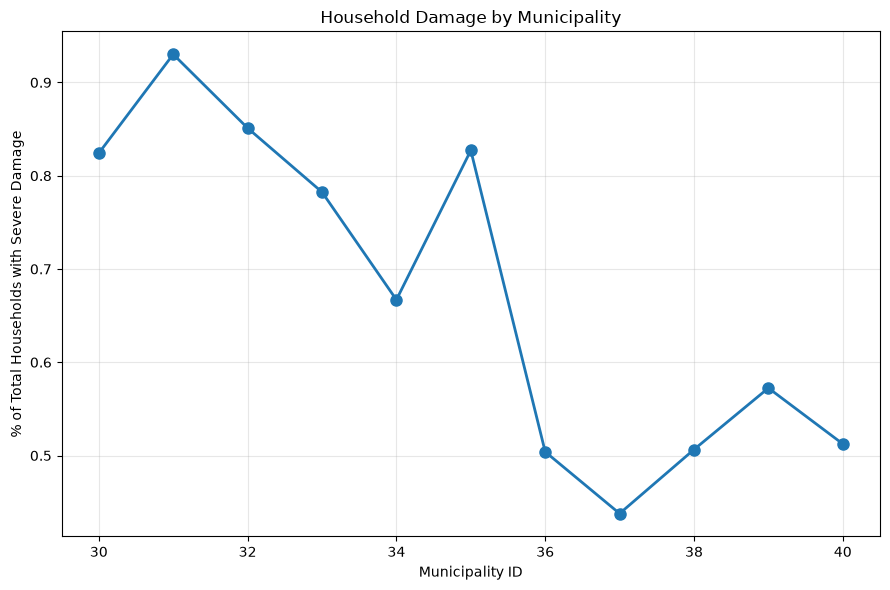

In [34]:
# Sort by municipality ID for line plot
damage_by_municipality_sorted = damage_by_municipality.sort_index()

# Create line plot
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(damage_by_municipality_sorted.index,
        damage_by_municipality_sorted['damage_rate'],
        marker='o', linewidth=2, markersize=8)
ax.set_xlabel('Municipality ID')
ax.set_ylabel('% of Total Households with Severe Damage')
ax.set_title('Household Damage by Municipality')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

16. Proporsi Kasta Gurung

- Menghitung persentase rumah tangga Gurung per kotamadya dan menggabungkannya ke tabel kerusakan.
- Kotamadya 35 sangat Gurung (82,7%) dan kerusakannya 82,7%.

In [35]:
# Calculate proportion of Gurung households by municipality
gurung_by_municipality = (
    df[df['caste_household'] == 'Gurung']
    .groupby('vdcmun_id')
    .size()
)

# Total households by municipality
total_by_municipality = df.groupby('vdcmun_id').size()

# Calculate proportion
damage_by_municipality['gurung_pct'] = (
    gurung_by_municipality / total_by_municipality
).fillna(0)

print("Gurung population by municipality:")
print(damage_by_municipality[['damage_rate', 'gurung_pct']].sort_values('gurung_pct', ascending=False))

Gurung population by municipality:
           damage_rate  gurung_pct
vdcmun_id                         
35            0.827145    0.826889
32            0.851117    0.387849
34            0.666979    0.385084
30            0.824201    0.338152
31            0.930199    0.326937
40            0.512444    0.246727
36            0.503972    0.143178
39            0.572344    0.097971
37            0.437789    0.050485
38            0.506425    0.049023
33            0.782464    0.011943


17. Proporsi Kasta Kumal + Korelasi

- Proporsi Kumal per kotamadya (terbesar di ID 38: 10%).
- Korelasi kerusakan dengan % Gurung: +0,570; dengan % Kumal: -0,566.

In [36]:
# Calculate proportion of Kumal households by municipality
kumal_by_municipality = (
    df[df['caste_household'] == 'Kumal']
    .groupby('vdcmun_id')
    .size()
)

# Calculate proportion (NaN will become 0)
damage_by_municipality['kumal_pct'] = (
    kumal_by_municipality / total_by_municipality
).fillna(0)

print("Kumal population by municipality:")
print(damage_by_municipality[['damage_rate', 'kumal_pct']].sort_values('kumal_pct', ascending=False))

# Show correlation
print(f"\nCorrelation between damage rate and Gurung population: {damage_by_municipality['damage_rate'].corr(damage_by_municipality['gurung_pct']):.3f}")
print(f"Correlation between damage rate and Kumal population: {damage_by_municipality['damage_rate'].corr(damage_by_municipality['kumal_pct']):.3f}")

Kumal population by municipality:
           damage_rate  kumal_pct
vdcmun_id                        
38            0.506425   0.100686
37            0.437789   0.048842
40            0.512444   0.036973
33            0.782464   0.029478
36            0.503972   0.003282
39            0.572344   0.000267
31            0.930199   0.000000
35            0.827145   0.000000
32            0.851117   0.000000
34            0.666979   0.000000
30            0.824201   0.000000

Correlation between damage rate and Gurung population: 0.570
Correlation between damage rate and Kumal population: -0.566


Kesimpulan Singkat

- Tujuan: memprediksi kerusakan parah rumah tangga di Gorkha dengan menggabungkan data demografi dan struktur bangunan, bukan hanya struktur seperti proyek sebelumnya.
- Performa: akurasi uji 72,36%, naik ±9 poin dari baseline 63,17%, dan lebih baik dari model sebelumnya (70,1%), menandakan tambahan fitur membantu. Selisih train-test kecil (tidak overfitting).
- Faktor struktural dominan: bangunan batu/lumpur, atap kayu/bambu, dan pondasi non-beton meningkatkan risiko 2-3,5x; material beton bertulang/bata semen justru menurunkannya hingga setengah.
- Pola geografis kuat: kerusakan sangat bervariasi antar kotamadya (43%-93%), dengan wilayah 30-35 paling parah.
- Peringatan interpretasi: korelasi dengan komposisi kasta (Gurung +0,57, Kumal -0,57) hanya berbasis 11 kotamadya, sehingga lemah secara statistik dan kemungkinan merupakan confounding dari lokasi (jarak ke pusat gempa, jenis bangunan), bukan efek kasta itu sendiri. Hal sama berlaku untuk variabel gender kepala keluarga.

Saran: skalakan fitur numerik (atasi warning), tambahkan precision/recall/AUC, coba Random Forest atau Gradient Boosting, dan gunakan model multilevel atau fitur lokasi agar efek wilayah tidak tercampur dengan efek demografi.